# Bài 16 · Dữ liệu nhãn: chất lượng, nhãn yếu, học tích cực và tăng cường

**Thời lượng gợi ý:** 180 phút · **Cần:** Bài 3 (và nên có Bài 10) · **Không cần GPU**

> **Bài mở rộng.** Từ Bài 3 đến Bài 15 ta *luôn có sẵn* tập dữ liệu có nhãn. Ngoài đời, nhãn mới là phần **đắt nhất** và thường là nút thắt thật sự của dự án NLP: ai gán, gán bao nhiêu, gán có đáng tin không, và có cách nào cần ít nhãn hơn không. Bài này đo từng câu hỏi đó trên dữ liệu thật.

## Mục tiêu

1. Vẽ **đường cong học** để trả lời "cần bao nhiêu nhãn?" bằng số đo thay vì cảm giác.
2. Đo chất lượng nhãn: **hệ số đồng thuận Cohen's κ** (tự cài), vì sao độ đồng thuận thô gây hiểu lầm, và **nhiễu nhãn ảnh hưởng thế nào** khi nó nằm ở tập huấn luyện so với tập đánh giá.
3. **Phát hiện nhãn nghi sai** bằng xác suất dự đoán chéo (ý tưởng của *confident learning*) và đo lợi ích khi làm sạch.
4. Viết **hàm gán nhãn** (nhãn yếu) và đo xem nhãn yếu thay được bao nhiêu nhãn thật.
5. Mô phỏng **học tích cực** (active learning) và so với chọn ngẫu nhiên.
6. Thử **tăng cường dữ liệu** và kiểm tra nó có giữ nguyên nhãn không.
7. Biết quy trình gán nhãn thực tế và chọn biện pháp theo ngân sách.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import re, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import vstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

from nlpvi import load_splits, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

## 1. Dữ liệu và đường cong học

Dùng **UIT-VSFC** (phản hồi của sinh viên, 3 lớp cảm xúc) như Bài 10: ≈ 11,4 nghìn câu train, **lớp "trung tính" chỉ chiếm ≈ 4%**. Mô hình là TF-IDF (1–2 gram) + hồi quy logistic có `class_weight="balanced"` — rẻ, chạy tính bằng giây nên ta có thể lặp hàng trăm lần để lấy trung bình. Điểm đánh giá luôn là **macro-F1 trên tập test** (xem Bài 3: accuracy che lớp hiếm).

Bộ vector hóa TF-IDF được học từ **văn bản** của toàn bộ tập train (không dùng nhãn): trong bài toán thật ta có sẵn một kho văn bản chưa gán nhãn.

UIT-VSFC: train 11,426 | test 3,166 | tỉ lệ lớp train: {'tiêu cực': np.float64(0.466), 'trung tính': np.float64(0.04), 'tích cực': np.float64(0.494)}


,macro-F1,độ lệch chuẩn
số nhãn,,
50,0.521,0.008
100,0.541,0.011
200,0.563,0.015
500,0.596,0.011
1000,0.637,0.006
2000,0.668,0.008
5000,0.714,0.016
11426,0.736,0.000


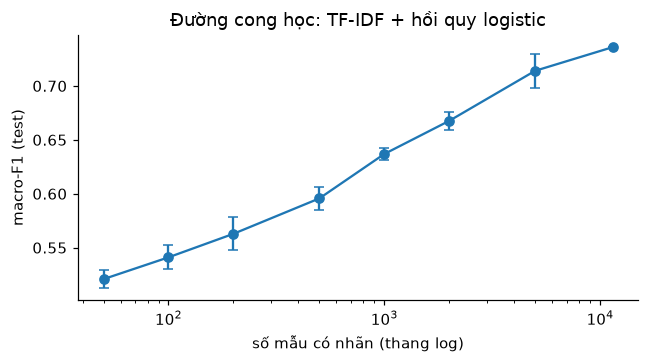

10s


In [2]:
TEN_LOP = ["tiêu cực", "trung tính", "tích cực"]          # chỉ số lớp 0, 1, 2

def tai_du_lieu():
    try:
        from datasets import load_dataset
        ds = load_dataset("uitnlp/vietnamese_students_feedback", revision="refs/convert/parquet")
        d = {k: ds[k].to_pandas().rename(columns={"sentence": "text", "sentiment": "y"})[["text", "y"]] for k in ("train", "validation", "test")}
        return d["train"], d["validation"], d["test"], "UIT-VSFC"
    except Exception as e:
        print(f"⚠ Không tải được UIT-VSFC ({type(e).__name__}); dùng bộ đánh giá tổng hợp (1,8 nghìn mẫu): các con số sẽ khác nhiều.")
        tr, va, te = load_splits()
        m = {"tiêu cực": 0, "trung tính": 1, "tích cực": 2}
        f = lambda d: pd.DataFrame({"text": d["text"], "y": d["label"].map(m)})
        return f(tr), f(va), f(te), "tổng hợp"

tr, va, te, NGUON = tai_du_lieu()
ttr, ytr, tte, yte = tr["text"].tolist(), tr["y"].values, te["text"].tolist(), te["y"].values
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(ttr)
Xtr, Xte = vec.transform(ttr), vec.transform(tte)
print(f"{NGUON}: train {len(ytr):,} | test {len(yte):,} | tỉ lệ lớp train:", dict(zip(TEN_LOP, np.round(np.bincount(ytr) / len(ytr), 3))))

mo_hinh = lambda: LogisticRegression(C=10, max_iter=2000, class_weight="balanced")
mf1 = lambda y, p: f1_score(y, p, average="macro")

def lay_mau(n, seed):
    """Lấy n chỉ số ngẫu nhiên có PHÂN TẦNG theo lớp (để không mất hẳn lớp hiếm khi n nhỏ)."""
    if n >= len(ytr):
        return np.arange(len(ytr))
    return train_test_split(np.arange(len(ytr)), train_size=n, stratify=ytr, random_state=seed)[0]

def duong_cong_hoc(sizes, so_seed=5):
    rows = []
    for n in sizes:
        diem = [mf1(yte, mo_hinh().fit(Xtr[lay_mau(n, s)], ytr[lay_mau(n, s)]).predict(Xte)) for s in range(so_seed if n < len(ytr) else 1)]
        rows.append({"số nhãn": n, "macro-F1": np.mean(diem), "độ lệch chuẩn": np.std(diem)})
    return pd.DataFrame(rows).set_index("số nhãn")

t0 = time.time()
dc = duong_cong_hoc([50, 100, 200, 500, 1000, 2000, 5000, len(ytr)])
display(dc.round(3))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.errorbar(dc.index, dc["macro-F1"], yerr=dc["độ lệch chuẩn"], marker="o", capsize=3)
ax.set_xscale("log"); ax.set_xlabel("số mẫu có nhãn (thang log)"); ax.set_ylabel("macro-F1 (test)")
ax.set_title("Đường cong học: TF-IDF + hồi quy logistic"); plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f}s")

**Đọc kết quả (1).**

- Macro-F1 tăng đều theo *logarit* của số nhãn: 0,52 (50 nhãn) → 0,56 (200) → 0,64 (1.000) → 0,71 (5.000) → 0,736 (toàn bộ 11,4 nghìn). Mỗi lần nhân ≈ 10 số nhãn (200 → 2.000, 500 → 5.000) cộng khoảng 0,10–0,12 điểm.
- Đường cong **chưa phẳng** ở cuối: từ 5.000 lên 11.426 nhãn (×2,3) vẫn thêm 0,022. Ở khoảng giữa, gấp đôi số nhãn mua được 0,03–0,04 (500 → 1.000: +0,041; 1.000 → 2.000: +0,031).
- Độ lệch chuẩn qua 5 lần lấy mẫu chỉ ≈ 0,01: *số lượng* nhãn quan trọng hơn nhiều so với việc may rủi chọn phải mẫu nào.
- Dùng đường cong này để quyết định: nó cho biết *lợi ích biên* của nhãn thêm, thứ cần ước lượng **trước** khi thuê người gán nhãn.

## 2. Chất lượng nhãn

### 2.1 Độ đồng thuận giữa người gán: Cohen's κ

Khi hai người gán nhãn độc lập cho cùng một tập mẫu, **độ đồng thuận thô** $p_o$ (tỉ lệ hai người gán giống nhau) dễ gây hiểu lầm: nếu một lớp chiếm 95% thì hai người gán *ngẫu nhiên theo tần suất* cũng khớp ≈ 90%. Cohen's κ trừ đi phần khớp "do ngẫu nhiên":

$$\kappa=\frac{p_o-p_e}{1-p_e},\qquad p_e=\sum_c p_A(c)\,p_B(c)$$

trong đó $p_A(c),p_B(c)$ là tỉ lệ người A, B gán lớp $c$. κ = 1: đồng thuận hoàn toàn; κ ≈ 0: chỉ bằng ngẫu nhiên.

Ta không có nhãn của nhiều người gán cho UIT-VSFC, nên **mô phỏng**: lấy nhãn trong tập làm "chân lý" rồi cho hai người gán độc lập, mỗi người có mô hình nhầm lẫn giống thực tế — *câu rõ cực tính ít bị gán sai, câu "trung tính" thì rất dễ bị đẩy sang tích cực/tiêu cực*. Đây là mô phỏng để học khái niệm, không phải số đo độ tin cậy của UIT-VSFC.

In [3]:
def kappa(a, b, K=3):
    a, b = np.asarray(a), np.asarray(b)
    po = np.mean(a == b)
    pe = float((np.bincount(a, minlength=K) / len(a) * np.bincount(b, minlength=K) / len(b)).sum())
    return (po - pe) / (1 - pe)

def nguoi_gan(y, rng, sang_trung_tinh=0.03, dao_cuc=0.01, trung_tinh_lech=0.40):
    """Mô phỏng một người gán: lớp cực tính hiếm khi sai (hay do dự thành 'trung tính'); câu trung tính hay bị đẩy sang cực tính."""
    out = y.copy()
    u = rng.random(len(y))
    cuc = y != 1
    out[cuc & (u < sang_trung_tinh)] = 1
    sai_cuc = cuc & (u >= sang_trung_tinh) & (u < sang_trung_tinh + dao_cuc)
    out[sai_cuc] = 2 - y[sai_cuc]                                     # đảo tiêu cực <-> tích cực
    tt = (y == 1) & (u < trung_tinh_lech)
    out[tt] = rng.choice([0, 2], tt.sum())
    return out

rng = np.random.default_rng(0)
A, B = nguoi_gan(ytr, rng), nguoi_gan(ytr, rng)
po = np.mean(A == B)
print(f"Độ đồng thuận thô A–B: {po:.3f} | κ (tự cài): {kappa(A, B):.3f} | κ (scikit-learn): {cohen_kappa_score(A, B):.3f}")
print(f"Độ chính xác của A so với chân lý: {np.mean(A == ytr):.3f}")
rows = []
for c, ten in enumerate(TEN_LOP):
    a_c, b_c = (A == c).astype(int), (B == c).astype(int)
    rows.append({"lớp": ten, "tỉ lệ (chân lý)": round(np.mean(ytr == c), 3), "đồng thuận thô (nhị phân)": round(np.mean(a_c == b_c), 3), "κ riêng lớp": round(kappa(a_c, b_c, 2), 3)})
display(pd.DataFrame(rows).set_index("lớp"))

Độ đồng thuận thô A–B: 0.907 | κ (tự cài): 0.830 | κ (scikit-learn): 0.830
Độ chính xác của A so với chân lý: 0.947


,tỉ lệ (chân lý),đồng thuận thô (nhị phân),κ riêng lớp
lớp,,,
tiêu cực,0.466,0.945,0.889
trung tính,0.040,0.926,0.268
tích cực,0.494,0.942,0.884


**Đọc kết quả (2.1).** Hai người gán (người A đúng 94,7% so với chân lý) có đồng thuận thô 0,907 và κ = 0,830 (khớp với scikit-learn). Nhưng nhìn **theo lớp**: lớp "trung tính" (4%) chỉ có κ = **0,268** dù đồng thuận thô nhị phân (là-trung-tính / không) là 0,926. Lý do: với lớp hiếm, hai người đều "không gán trung tính" cho gần hết mẫu nên khớp *ngẫu nhiên* kỳ vọng đã ≈ 0,90; 0,926 chỉ hơn mức đó chút ít. Hai bài học: (1) đồng thuận thô cao có thể che sự bất đồng ở đúng lớp bạn quan tâm; (2) báo cáo κ **theo từng lớp**, giống như macro-F1. (Đây là mô phỏng với mô hình nhầm lẫn do chúng tôi đặt ra, không phải số đo độ tin cậy của UIT-VSFC.)

### 2.2 Nhiễu nhãn nằm ở tập train hay tập test?

Giả sử một tỉ lệ $p$ nhãn bị gán sai (chuyển sang một lớp khác ngẫu nhiên). Ảnh hưởng khác hẳn tùy nó nằm ở đâu:

- **Nhiễu ở tập train** (đánh giá trên test sạch): mô hình học từ nhãn sai → *mô hình tệ đi thật*.
- **Nhiễu ở tập test** (mô hình huấn luyện sạch): mô hình không đổi nhưng *thước đo bị sai* → ta thấy điểm thấp hơn thực tế, không biết mô hình tốt đến đâu.

,nhiễu ở TRAIN,nhiễu ở TEST
tỉ lệ nhiễu,,
0.0,0.736,0.736
0.1,0.667,0.649
0.2,0.617,0.585
0.3,0.567,0.524
0.4,0.514,0.459


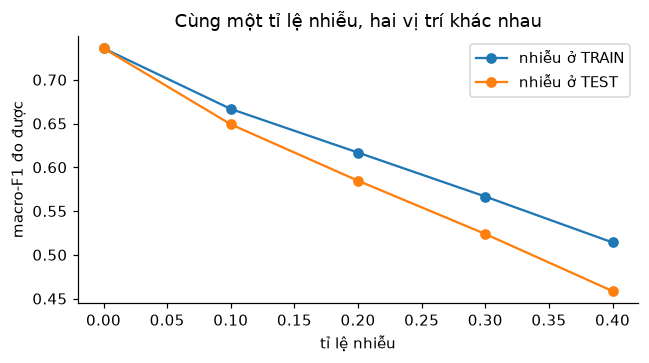

In [4]:
def nhieu_doi_xung(y, p, rng):
    y2 = y.copy(); m = rng.random(len(y)) < p
    y2[m] = (y[m] + rng.integers(1, 3, m.sum())) % 3                  # chuyển sang một trong hai lớp còn lại
    return y2

sach = mo_hinh().fit(Xtr, ytr)
p_sach = sach.predict(Xte)
rows = []
for p in [0.0, 0.1, 0.2, 0.3, 0.4]:
    a, b = [], []
    for seed in range(3):
        r = np.random.default_rng(seed)
        a.append(mf1(yte, mo_hinh().fit(Xtr, nhieu_doi_xung(ytr, p, r)).predict(Xte)))          # nhiễu ở train, test sạch
        b.append(mf1(nhieu_doi_xung(yte, p, r), p_sach))                                         # train sạch, nhiễu ở test
    rows.append({"tỉ lệ nhiễu": p, "nhiễu ở TRAIN": np.mean(a), "nhiễu ở TEST": np.mean(b)})
nz = pd.DataFrame(rows).set_index("tỉ lệ nhiễu")
display(nz.round(3))
ax = nz.plot(marker="o", figsize=(6, 3.4)); ax.set_ylabel("macro-F1 đo được"); ax.set_title("Cùng một tỉ lệ nhiễu, hai vị trí khác nhau")
plt.tight_layout(); plt.show()

**Đọc kết quả (2.2).** Với cùng tỉ lệ nhiễu, nhiễu ở **tập test** làm điểm đo được thấp hơn nhiễu ở tập train ở mọi mức (p = 0,2: 0,585 so với 0,617), trong khi mô hình huấn luyện sạch *không hề đổi*. Nghĩa là nếu nhãn tập đánh giá nhiễu 20%, ta tưởng mô hình tệ đi 0,15 điểm: **không thể đo một mô hình tốt hơn chất lượng nhãn của tập đánh giá cho phép**. Nhiễu ở train cũng đau: 20% nhãn sai làm mất 0,12 điểm (0,736 → 0,617), mức mà theo đường cong ở mục 1 tương ứng với việc chỉ có khoảng 500–1.000 nhãn sạch. (Bài tập 2 thử các kiểu nhiễu khác: không phải nhãn sai nào cũng hại như nhau.)

### 2.3 Phát hiện nhãn nghi sai (confident learning rút gọn)

Ý tưởng: huấn luyện mô hình bằng **kiểm tra chéo** để mỗi mẫu có xác suất dự đoán từ một mô hình *chưa thấy nó*. Nếu mô hình rất tự tin rằng mẫu thuộc lớp $c'$ nhưng nhãn ghi là $c\neq c'$ thì mẫu đó **nghi là gán sai**. "Tự tin" được định nghĩa theo từng lớp: xác suất vượt *độ tự tin trung bình* của lớp $c'$ trên các mẫu được gán đúng lớp đó. Ta tiêm 20% nhiễu vào train (để biết đáp án thật), gắn cờ, rồi loại các mẫu bị gắn cờ và huấn luyện lại.

In [5]:
def gan_co_nghi_sai(X, y, so_fold=5, seed=0):
    P = cross_val_predict(mo_hinh(), X, y, cv=StratifiedKFold(so_fold, shuffle=True, random_state=seed), method="predict_proba")
    nguong = np.array([P[y == c, c].mean() for c in range(3)])           # độ tự tin trung bình của từng lớp
    du_doan = P.argmax(1)
    co = (du_doan != y) & (P[np.arange(len(y)), du_doan] >= nguong[du_doan])
    return co, P

y_nhieu = nhieu_doi_xung(ytr, 0.20, np.random.default_rng(0))
sai_that = y_nhieu != ytr
co, P = gan_co_nghi_sai(Xtr, y_nhieu)
tp = (co & sai_that).sum()
print(f"Tiêm 20% nhiễu: {sai_that.sum()} nhãn sai thật. Gắn cờ {co.sum()} mẫu | precision {tp / co.sum():.2f} (cờ đúng) | recall {tp / sai_that.sum():.2f} (bắt được bao nhiêu nhãn sai)")
giu = ~co
display(pd.DataFrame({"macro-F1 test": {
    "nhãn sạch (mốc trên)": mf1(yte, sach.predict(Xte)),
    "nhiễu 20%, giữ tất cả": mf1(yte, mo_hinh().fit(Xtr, y_nhieu).predict(Xte)),
    "nhiễu 20%, loại mẫu bị gắn cờ": mf1(yte, mo_hinh().fit(Xtr[giu], y_nhieu[giu]).predict(Xte))}}).round(3))

Tiêm 20% nhiễu: 2322 nhãn sai thật. Gắn cờ 3295 mẫu | precision 0.51 (cờ đúng) | recall 0.72 (bắt được bao nhiêu nhãn sai)


,macro-F1 test
nhãn sạch (mốc trên),0.736
"nhiễu 20%, giữ tất cả",0.613
"nhiễu 20%, loại mẫu bị gắn cờ",0.685


**Đọc kết quả (2.3).** Với 20% nhiễu tiêm vào, quy trình gắn cờ 3.295 mẫu: **precision 0,51** (một nửa số cờ là nhãn sai thật) và **recall 0,72**. Dù chưa hoàn hảo, loại các mẫu bị gắn cờ nâng macro-F1 từ 0,613 lên **0,685**, lấy lại ≈ 59% phần đã mất so với nhãn sạch (0,736), dù ta cũng vứt đi ≈ 1.600 mẫu *đúng* bị gắn cờ nhầm. Nhưng đây là nhiễu **ngẫu nhiên đối xứng** — loại thường dễ phát hiện nhất; nhiễu có hệ thống (người gán luôn hiểu sai một khái niệm) thường khó bắt hơn nhiều, và ở đây ta chưa đo điều đó.

Còn trên nhãn **gốc** (không tiêm gì): nhãn nào của UIT-VSFC bị mô hình "phản đối" mạnh nhất? Ta in 12 mẫu có xác suất nhãn-đã-ghi thấp nhất trong các mẫu bị gắn cờ, để một con người đọc và quyết định. Đây mới là cách dùng thật: *thu hẹp* hàng chục nghìn mẫu xuống một danh sách ngắn để người rà soát, không tự động sửa.

In [6]:
co_goc, P_goc = gan_co_nghi_sai(Xtr, ytr)
idx = np.where(co_goc)[0]
idx = idx[np.argsort(P_goc[idx, ytr[idx]])][:12]
print(f"Gắn cờ {co_goc.sum()} / {len(ytr)} nhãn gốc ({co_goc.mean():.1%}). 12 mẫu nghi ngờ nhất:\n")
display(pd.DataFrame({"câu": [ttr[i][:140] for i in idx], "nhãn đã ghi": [TEN_LOP[ytr[i]] for i in idx],
                      "mô hình dự đoán": [TEN_LOP[P_goc[i].argmax()] for i in idx], "P(nhãn đã ghi)": P_goc[idx, ytr[idx]].round(3)}))

Gắn cờ 557 / 11426 nhãn gốc (4.9%). 12 mẫu nghi ngờ nhất:



,câu,nhãn đã ghi,mô hình dự đoán,P(nhãn đã ghi)
0,không co ý kiến .,tích cực,trung tính,0.000
1,dễ .,trung tính,tích cực,0.000
2,"cô dạy nhanh quá , khó hiểu dẫn đến chán nản .",tích cực,tiêu cực,0.000
3,"giảng viên tận tình chu đáo , truyền đạt dễ hi...",tiêu cực,tích cực,0.000
4,"tiếng anh không phải là môn dạy lý thuyết , ng...",tích cực,tiêu cực,0.000
5,"thầy nên dạy nhiều hơn , nên dạy kỹ lý thuyết ...",tích cực,tiêu cực,0.001
6,chưa có .,trung tính,tiêu cực,0.001
7,"nhiệt tình , tận tâm , giải đáp các thắc mắc .",tiêu cực,tích cực,0.001
8,"hướng dẫn , giảng dạy .",trung tính,tích cực,0.001
9,"cho nghỉ học quá nhiều , bù học vào các ngày c...",tích cực,tiêu cực,0.001


**Đọc kết quả (2.3b).** Đây là cách đọc của chúng tôi (bạn hãy tự đọc 12 câu rồi so, có thể bạn không đồng ý): **5 câu nhãn sai rõ ràng** (#0 "không có ý kiến" gán tích cực; #2 "khó hiểu dẫn đến chán nản" gán tích cực; #3 "tận tình chu đáo, truyền đạt dễ hiểu" gán tiêu cực; #7 "nhiệt tình, tận tâm" gán tiêu cực; #10 "không cung cấp tài liệu… chưa tốt" gán tích cực), **2 câu nhiều khả năng sai** (#4 và #9: góp ý/phàn nàn gán tích cực), **3 câu mơ hồ** cần quy ước trong hướng dẫn gán nhãn (#1 "dễ .", #5 câu góp ý "thầy nên dạy nhiều hơn", #11 "rất ít nổi nóng") và **2 câu mà chính mô hình mới sai** (#6 "chưa có ." và #8 "hướng dẫn, giảng dạy ." với nhãn trung tính hợp lý). Vậy trong 12 câu đáng ngờ nhất, khoảng một nửa trở lên là nhãn sai thật — một danh sách ngắn rất đáng cho người rà soát — nhưng mô hình cũng sai ở 2/12, nên đây là *gợi ý để người xem lại*, không phải thứ để tự động sửa. Các câu **góp ý** ("nên…") rõ ràng là vùng xám cần một quy ước thống nhất.

## 3. Nhãn yếu (weak supervision)

Thay vì gán nhãn từng mẫu, ta viết các **hàm gán nhãn** (labeling functions, LF): mỗi hàm là một luật đơn giản — từ điển, mẫu regex, từ khóa chủ đề — *có thể bỏ qua* (không biết) hoặc gán một nhãn. Chúng ồn, phủ không hết, và có thể mâu thuẫn nhau, nhưng chạy trên cả kho văn bản chỉ mất vài giây. Câu hỏi: gộp các nhãn ồn ấy lại có huấn luyện được mô hình tốt không?

Ta viết 8 LF cho UIT-VSFC: từ điển khen/chê, câu góp ý ("nên", "mong"), lời cảm ơn, từ khóa về cơ sở vật chất/chương trình (các chủ đề này nghiêng hẳn về tiêu cực), phủ định trước từ khen, câu ngắn khen, câu trung tính. **Đây là những luật do người viết nhìn dữ liệu mà nghĩ ra** — nếu bạn cũng nhìn nhãn thật để chỉnh luật thì bạn đang "học thuộc" tập đó; vì vậy phần đo bên dưới dùng *tập dev 200 mẫu* như ngoài đời.

In [7]:
KHEN = ["tốt", "hay", "nhiệt tình", "tận tâm", "dễ hiểu", "vui tính", "hài lòng", "thân thiện", "tuyệt vời", "chu đáo", "giỏi", "bổ ích", "thú vị", "hữu ích",
        "sinh động", "tâm huyết", "nhiệt huyết", "yêu thích", "dễ thương", "cảm ơn", "cám ơn", "tuyệt", "xuất sắc", "chuyên nghiệp", "ấn tượng", "gần gũi"]
CHE = ["chưa", "kém", "tệ", "chán", "khó", "thiếu", "lỗi", "hạn chế", "bất cập", "nhàm", "hỏng", "bẩn", "lãng phí", "phí", "nóng", "ồn", "cũ", "chậm",
       "nhanh quá", "quá nhanh", "không thể", "không rõ", "không hiểu", "không được", "bất tiện", "thất vọng", "mệt", "áp lực", "dài dòng", "lan man"]
GOP_Y = ["nên", "mong", "cần", "đề nghị", "hy vọng", "ước gì", "giá như", "muốn"]
CSVC = ["wifi", "máy chiếu", "phòng học", "căn tin", "nhà vệ sinh", "máy lạnh", "máy điều hòa", "ghế", "thư viện", "nhà xe", "ký túc", "điện", "mạng", "âm thanh",
        "micro", "quạt", "phòng thí nghiệm", "wc"]
CHUONG_TRINH = ["chương trình", "môn học", "tín chỉ", "học phí", "lịch học", "thời khóa biểu", "giáo trình", "đề cương", "thi", "đăng ký", "học phần", "môn"]
TRUNG_TINH = ["bình thường", "không có ý kiến", "không có góp ý", "không có", "tạm được", "tạm ổn"]
dem = lambda t, ws: sum(w in t for w in ws)
NEG, NEU, POS = 0, 1, 2

def lf_tu_dien(t):
    k, c = dem(t, KHEN), dem(t, CHE)
    return POS if k > c else (NEG if c > k else None)
def lf_gop_y(t): return NEG if dem(t, GOP_Y) else None
def lf_cam_on(t): return POS if ("cảm ơn" in t or "cám ơn" in t) else None
def lf_co_so_vat_chat(t): return NEG if dem(t, CSVC) else None
def lf_chuong_trinh(t): return NEG if dem(t, CHUONG_TRINH) else None
def lf_trung_tinh(t): return NEU if dem(t, TRUNG_TINH) else None
def lf_phu_dinh_khen(t): return NEG if re.search(r"\b(chưa|không)\s+(tốt|hay|rõ|hiểu|nhiệt|tận|phù hợp|hợp lý|đủ)", t) else None
def lf_cau_ngan_khen(t): return POS if len(t.split()) <= 6 and dem(t, ["tốt", "nhiệt tình", "tuyệt", "hay", "dễ hiểu", "vui"]) and not dem(t, ["không", "chưa"]) else None
LFS = [lf_tu_dien, lf_gop_y, lf_cam_on, lf_co_so_vat_chat, lf_chuong_trinh, lf_trung_tinh, lf_phu_dinh_khen, lf_cau_ngan_khen]

L = np.array([[(-1 if (v := f(t.lower())) is None else v) for f in LFS] for t in ttr])          # -1 = bỏ qua
dev = lay_mau(200, 123)                                          # tập dev 200 mẫu có nhãn (thứ duy nhất ta "được phép" nhìn)
rows = []
for j, f in enumerate(LFS):
    phu = L[:, j] >= 0; phu_dev = phu[dev]
    rows.append({"hàm gán nhãn": f.__name__, "phủ (cả kho)": round(phu.mean(), 3),
                 "độ chính xác ước lượng từ dev": round(float((L[dev, j] == ytr[dev])[phu_dev].mean()), 2) if phu_dev.sum() >= 3 else None, "số mẫu dev": int(phu_dev.sum()),
                 "độ chính xác THẬT (cả kho)*": round(float((L[phu, j] == ytr[phu]).mean()), 3)})
display(pd.DataFrame(rows).set_index("hàm gán nhãn"))
print("* chỉ tính được vì ta giữ nhãn của cả kho để làm bài giảng; ngoài đời bạn chỉ có cột ước lượng từ dev.")

,phủ (cả kho),độ chính xác ước lượng từ dev,số mẫu dev,độ chính xác THẬT (cả kho)*
hàm gán nhãn,,,,
lf_tu_dien,0.537,0.92,113,0.886
lf_gop_y,0.176,0.92,37,0.905
lf_cam_on,0.006,NaN,0,0.531
lf_co_so_vat_chat,0.027,1.00,4,0.935
lf_chuong_trinh,0.166,0.76,33,0.686
lf_trung_tinh,0.021,NaN,1,0.236
lf_phu_dinh_khen,0.033,1.00,5,0.901
lf_cau_ngan_khen,0.039,0.80,10,0.942


* chỉ tính được vì ta giữ nhãn của cả kho để làm bài giảng; ngoài đời bạn chỉ có cột ước lượng từ dev.


**Đọc kết quả (3a).** Hầu hết LF chính xác 0,69–0,94 ở nơi chúng gán nhãn (cột "THẬT"), nhưng độ phủ chênh nhau rất xa: từ điển khen/chê phủ 54% kho, các LF còn lại từ 0,6% đến 18%. **Ước lượng từ dev 200 mẫu lệch nhiều hoặc không có**: `lf_chuong_trinh` ước 0,76 (33 mẫu) so với thật 0,69; `lf_cam_on` không có mẫu dev nào; `lf_trung_tinh` chỉ có **1** mẫu dev (không ước được) trong khi độ chính xác thật chỉ **0,24**. Lớp hiếm lại là nơi một tập dev nhỏ không đủ để *đánh giá* các LF — vấn đề lớp hiếm xuất hiện ở mọi bước của bài này.

### 3.1 Gộp các nhãn ồn rồi huấn luyện

Hai cách gộp: **bỏ phiếu đa số** (bỏ qua hàm không biết; hòa thì bỏ qua mẫu) và **bỏ phiếu có trọng số** theo độ chính xác ước lượng từ dev, $w_j=\log\frac{(K-1)\,\hat a_j}{1-\hat a_j}$ (ý tưởng của mô hình sinh nhãn, rút gọn). Rồi huấn luyện mô hình trên các mẫu được gán nhãn yếu và so với:

- **200 nhãn thật** (cùng ngân sách với tập dev), lặp 5 seed;
- **nhãn yếu + 200 nhãn thật** (nhãn yếu trọng số 0,3);
- **toàn bộ nhãn thật** (11,4 nghìn).

In [8]:
def bo_phieu_da_so(L):
    out = np.full(len(L), -1)
    for i, row in enumerate(L):
        v = Counter(x for x in row if x >= 0).most_common()
        if v and not (len(v) > 1 and v[0][1] == v[1][1]):
            out[i] = v[0][0]
    return out

acc_hat = np.array([((L[dev, j] == ytr[dev])[L[dev, j] >= 0].sum() + 1) / ((L[dev, j] >= 0).sum() + 2) for j in range(L.shape[1])])     # làm mịn Laplace
def bo_phieu_trong_so(L, K=3):
    w = np.log((K - 1) * acc_hat / (1 - acc_hat))
    out = np.full(len(L), -1)
    for i, row in enumerate(L):
        if (row >= 0).any():
            s = np.zeros(K)
            for j, x in enumerate(row):
                if x >= 0: s[x] += w[j]
            out[i] = s.argmax()
    return out

yw_mv, yw_w = bo_phieu_da_so(L), bo_phieu_trong_so(L)
print("độ chính xác ước lượng (làm mịn) và trọng số log-odds của từng LF:")
print(pd.DataFrame({"acc ước lượng": acc_hat.round(2), "trọng số": np.log(2 * acc_hat / (1 - acc_hat)).round(2)}, index=[f.__name__ for f in LFS]).T.to_string())
rows = []
for ten, yw in [("đa số", yw_mv), ("có trọng số", yw_w)]:
    m = yw >= 0
    rows.append({"cách gộp": ten, "phủ": round(m.mean(), 3), "độ chính xác nhãn yếu (THẬT)": round(float((yw[m] == ytr[m]).mean()), 3),
                 "nhãn yếu 'trung tính' (số mẫu)": int((yw[m] == 1).sum()), "nhãn thật 'trung tính' trong phần được phủ": int((ytr[m] == 1).sum())})
display(pd.DataFrame(rows).set_index("cách gộp"))

def f1_theo_lop(clf):
    return [round(float(x), 2) for x in f1_score(yte, clf.predict(Xte), average=None, labels=[0, 1, 2])]

m_mv = yw_mv >= 0
clf_yeu = mo_hinh().fit(Xtr[m_mv], yw_mv[m_mv])
gold200, hon_hop = [], []
for s in range(5):
    idx = lay_mau(200, s)
    c = mo_hinh().fit(Xtr[idx], ytr[idx]); gold200.append((mf1(yte, c.predict(Xte)), f1_theo_lop(c)))
    X2 = vstack([Xtr[m_mv], Xtr[idx]]); y2 = np.concatenate([yw_mv[m_mv], ytr[idx]]); w2 = np.concatenate([np.full(m_mv.sum(), 0.3), np.ones(len(idx))])
    c2 = mo_hinh().fit(X2, y2, sample_weight=w2); hon_hop.append((mf1(yte, c2.predict(Xte)), f1_theo_lop(c2)))
clf_day_du = mo_hinh().fit(Xtr, ytr)
ket_yeu = {
    f"nhãn yếu (đa số), {m_mv.sum():,} mẫu, 0 nhãn thật": (mf1(yte, clf_yeu.predict(Xte)), f1_theo_lop(clf_yeu)),
    "200 nhãn thật (TB 5 seed)": (np.mean([g[0] for g in gold200]), list(np.mean([g[1] for g in gold200], axis=0).round(2))),
    "nhãn yếu + 200 nhãn thật (TB 5 seed)": (np.mean([g[0] for g in hon_hop]), list(np.mean([g[1] for g in hon_hop], axis=0).round(2))),
    f"toàn bộ {len(ytr):,} nhãn thật": (mf1(yte, clf_day_du.predict(Xte)), f1_theo_lop(clf_day_du)),
}
display(pd.DataFrame([{"cách huấn luyện": k, "macro-F1": round(float(v[0]), 3), **{"F1 " + TEN_LOP[i]: v[1][i] for i in range(3)}} for k, v in ket_yeu.items()]).set_index("cách huấn luyện"))

độ chính xác ước lượng (làm mịn) và trọng số log-odds của từng LF:


               lf_tu_dien  lf_gop_y  lf_cam_on  lf_co_so_vat_chat  lf_chuong_trinh  lf_trung_tinh  lf_phu_dinh_khen  lf_cau_ngan_khen
acc ước lượng        0.91      0.90       0.50               0.83             0.74           0.33              0.86              0.75
trọng số             3.04      2.86       0.69               2.30             1.75          -0.00              2.48              1.79


,phủ,độ chính xác nhãn yếu (THẬT),nhãn yếu 'trung tính' (số mẫu),nhãn thật 'trung tính' trong phần được phủ
cách gộp,,,,
đa số,0.672,0.897,103,176
có trọng số,0.730,0.878,0,198


,macro-F1,F1 tiêu cực,F1 trung tính,F1 tích cực
cách huấn luyện,,,,
"nhãn yếu (đa số), 7,681 mẫu, 0 nhãn thật",0.585,0.81,0.11,0.83
200 nhãn thật (TB 5 seed),0.563,0.81,0.05,0.83
nhãn yếu + 200 nhãn thật (TB 5 seed),0.599,0.83,0.13,0.85
"toàn bộ 11,426 nhãn thật",0.736,0.91,0.38,0.92


**Đọc kết quả (3b).**

- **Gộp nhãn:** bỏ phiếu đa số phủ 67% kho với nhãn yếu chính xác 0,897; bỏ phiếu có trọng số phủ 73% nhưng chính xác 0,878 và **không gán nhãn "trung tính" nào** (0 mẫu): `lf_trung_tinh` chỉ có 1 mẫu dev nên độ chính xác ước lượng là 0,33 và trọng số log-odds bằng 0, tức luật này không bao giờ thắng. Cách đa số gán 103 mẫu "trung tính" (so với 176 mẫu thật trong phần được phủ).
- **Huấn luyện:** mô hình học từ nhãn yếu (7,7 nghìn mẫu, **0 nhãn thật**) đạt 0,585, nhỉnh hơn 200 nhãn thật (0,563); nhãn yếu + 200 nhãn thật đạt 0,599 — vẫn xa 0,736 của toàn bộ nhãn thật. Xem F1 theo lớp: hai lớp lớn chỉ kém trần một chút (0,81–0,85 so với 0,91–0,92) còn **"trung tính" gần như không học được** (0,11–0,13 so với 0,38): chính chỗ ta cần nhãn nhất thì các LF không giúp.
- **Bài học:** nhãn yếu thay được một phần nhãn thật *ở các lớp dễ*, nhưng thừa hưởng mọi thiên lệch của luật (ở đây luật gần như không biết đến lớp hiếm) và chỉ phủ phần dễ của kho (≈ 1/3 mẫu không được gán). Nó là công cụ để khởi động và để *tìm mẫu cần gán*, không thay thế tập vàng.

## 4. Học tích cực (active learning)

Nếu chỉ gán được $B$ nhãn, nên chọn **mẫu nào** để gán? Học tích cực lặp: huấn luyện mô hình trên các nhãn đang có → *chấm điểm "mức bất định"* cho các mẫu chưa gán → gán nhãn cho những mẫu bất định nhất → lặp lại. Ba cách chấm điểm phổ biến, với $p$ là phân phối dự đoán của mô hình:

- **Độ tự tin thấp nhất**: $1-\max_c p_c$;
- **Biên độ nhỏ nhất**: khoảng cách giữa hai xác suất lớn nhất (nhỏ = lưỡng lự giữa hai lớp);
- **Entropy**: $-\sum_c p_c\log p_c$.

Đối chứng là **chọn ngẫu nhiên**. Ta *mô phỏng* bằng cách "gán nhãn" chính là lấy nhãn có sẵn trong train. Khởi tạo: 5 mẫu mỗi lớp + ngẫu nhiên cho đủ 50; mỗi vòng thêm 50 nhãn đến 1000; lặp 5 seed; điểm là macro-F1 trên test.

122s


,ngẫu nhiên,độ tự tin thấp nhất,biên độ nhỏ nhất,entropy
số nhãn,,,,
100,0.531,0.543,0.547,0.534
200,0.567,0.566,0.575,0.559
400,0.588,0.611,0.607,0.593
600,0.613,0.642,0.638,0.621
800,0.625,0.657,0.654,0.645
1000,0.639,0.679,0.670,0.662


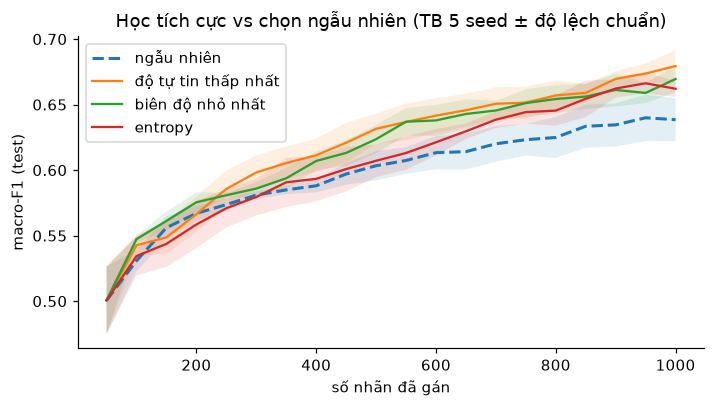

In [9]:
def hoc_tich_cuc(chien_luoc, seed, n0=50, buoc=50, tong=1000):
    r = np.random.default_rng(seed)
    khoi_tao = [i for c in range(3) for i in r.choice(np.where(ytr == c)[0], 5, replace=False)]
    con_lai = np.setdiff1d(np.arange(len(ytr)), khoi_tao)
    da_gan = khoi_tao + list(r.choice(con_lai, n0 - len(khoi_tao), replace=False))
    kho = np.setdiff1d(np.arange(len(ytr)), da_gan)
    duong = []
    while True:
        clf = mo_hinh().fit(Xtr[da_gan], ytr[da_gan])
        duong.append((len(da_gan), mf1(yte, clf.predict(Xte))))
        if len(da_gan) >= tong:
            break
        if chien_luoc == "ngẫu nhiên":
            q = r.choice(kho, buoc, replace=False)
        else:
            P = clf.predict_proba(Xtr[kho])
            if chien_luoc == "độ tự tin thấp nhất": diem = 1 - P.max(1)
            elif chien_luoc == "biên độ nhỏ nhất": ps = np.sort(P, 1); diem = -(ps[:, -1] - ps[:, -2])
            else: diem = -(P * np.log(P + 1e-12)).sum(1)
            q = kho[np.argsort(-diem)[:buoc]]
        da_gan += list(q); kho = np.setdiff1d(kho, q)
    return duong, np.array(da_gan)

t0 = time.time()
CHIEN_LUOC = ["ngẫu nhiên", "độ tự tin thấp nhất", "biên độ nhỏ nhất", "entropy"]
kq_al, gan_cuoi = {}, {}
for cl in CHIEN_LUOC:
    runs = [hoc_tich_cuc(cl, seed) for seed in range(5)]
    kq_al[cl] = np.array([[d[1] for d in r[0]] for r in runs])
    gan_cuoi[cl] = [r[1] for r in runs]
n_truc = [d[0] for d in runs[0][0]]
print(f"{time.time() - t0:.0f}s")
moc = [100, 200, 400, 600, 800, 1000]
display(pd.DataFrame({cl: {n: round(kq_al[cl][:, n_truc.index(n)].mean(), 3) for n in moc} for cl in CHIEN_LUOC}).rename_axis("số nhãn"))

fig, ax = plt.subplots(figsize=(6.6, 3.8))
for cl in CHIEN_LUOC:
    m, s = kq_al[cl].mean(0), kq_al[cl].std(0)
    ax.plot(n_truc, m, label=cl, lw=2 if cl == "ngẫu nhiên" else 1.5, ls="--" if cl == "ngẫu nhiên" else "-")
    ax.fill_between(n_truc, m - s, m + s, alpha=0.12)
ax.set_xlabel("số nhãn đã gán"); ax.set_ylabel("macro-F1 (test)"); ax.legend(); ax.set_title("Học tích cực vs chọn ngẫu nhiên (TB 5 seed ± độ lệch chuẩn)")
plt.tight_layout(); plt.show()

In [10]:
def nhan_can_de_dat(duong_tb, muc):
    for n, v in zip(n_truc, duong_tb):
        if v >= muc:
            return n
    return None

muc = round(kq_al["ngẫu nhiên"].mean(0)[-1], 3)                   # điểm chọn ngẫu nhiên đạt được ở 1000 nhãn
rows = []
for cl in CHIEN_LUOC:
    ty_le_tt = np.mean([np.mean(ytr[g] == 1) for g in gan_cuoi[cl]])
    rows.append({"chiến lược": cl, f"số nhãn để đạt {muc}": nhan_can_de_dat(kq_al[cl].mean(0), muc), "tỉ lệ 'trung tính' trong 1000 nhãn đã chọn": round(ty_le_tt, 3)})
display(pd.DataFrame(rows).set_index("chiến lược"))
print("Tỉ lệ 'trung tính' trong toàn kho:", round(np.mean(ytr == 1), 3))

,số nhãn để đạt 0.639,tỉ lệ 'trung tính' trong 1000 nhãn đã chọn
chiến lược,,
ngẫu nhiên,950,0.042
độ tự tin thấp nhất,600,0.152
biên độ nhỏ nhất,650,0.081
entropy,750,0.158


Tỉ lệ 'trung tính' trong toàn kho: 0.04


**Đọc kết quả (4).**

- Ở ≈ 200 nhãn trở xuống học tích cực **không hơn** chọn ngẫu nhiên (0,566 so với 0,567 ở 200 nhãn): mô hình ban đầu quá kém để biết mẫu nào "bất định" thật sự (vấn đề *khởi động nguội*). Từ ≈ 400 nhãn, các chiến lược theo độ bất định thắng: ở 1.000 nhãn, độ tự tin thấp nhất đạt 0,679, biên độ nhỏ nhất 0,670, entropy 0,662, so với 0,639 của chọn ngẫu nhiên (+0,040, +0,031, +0,023).
- Quy ra số nhãn: chọn ngẫu nhiên cần ≈ 950 nhãn để đạt 0,639; độ tự tin thấp nhất chỉ cần ≈ 600 (tiết kiệm ≈ 37%), biên độ nhỏ nhất ≈ 650, entropy ≈ 750.
- **Vì sao thắng:** các chiến lược này chọn nhiều mẫu **lớp hiếm** hơn hẳn: lớp "trung tính" chiếm 15% trong 1.000 nhãn được chọn (độ tự tin thấp nhất, entropy) và 8% (biên độ nhỏ nhất), so với 4% khi chọn ngẫu nhiên (đúng tỉ lệ của kho). Vì macro-F1 coi mọi lớp ngang nhau, nhận thêm mẫu lớp hiếm là lợi lớn.
- **Giới hạn của mô phỏng:** 5 seed, một mô hình, nhãn có sẵn nên không có chi phí thật và không có nhiễu người gán; ngoài đời, mẫu bất định nhất thường *cũng là mẫu người gán thấy khó nhất* nên nhãn của chúng ồn hơn. Mẫu chọn theo mô hình A có thể không còn tối ưu khi bạn đổi sang mô hình B (bài tập 5).

## 5. Tăng cường dữ liệu

Khi nhãn ít, ta có thể **sinh thêm mẫu** từ mẫu có sẵn bằng các biến đổi *giữ nguyên nhãn*. Hai biến đổi đơn giản mức từ: **xóa ngẫu nhiên** 15% từ, và **hoán đổi** hai từ kề nhau. Rủi ro lớn nhất: biến đổi làm **đổi nghĩa** (xóa "không" trong "không tốt" biến câu chê thành câu khen) nên nhãn cũ không còn đúng. Ta thử thêm biến thể **xóa nhưng giữ lại từ phủ định/hạn chế**.

Kiểm tra bằng hai cách: (1) tỉ lệ *dự đoán của một mô hình đã huấn luyện đầy đủ* bị đổi sau biến đổi — một chỉ báo thô cho việc đổi nhãn (mô hình không hoàn hảo, nên chỉ so sánh tương đối); (2) lợi ích khi huấn luyện với ít nhãn.

In [11]:
PHU_DINH = {"không", "chưa", "chẳng", "chả", "đừng", "thiếu", "khó"}

def xoa_ngau_nhien(toks, r, p=0.15, giu_phu_dinh=False):
    out = [w for w in toks if (giu_phu_dinh and w in PHU_DINH) or r.random() > p]
    return out or toks
def hoan_doi(toks, r, n=2):
    t = list(toks)
    for _ in range(n):
        if len(t) > 3:
            i = r.randrange(len(t) - 1); t[i], t[i + 1] = t[i + 1], t[i]
    return t
BIEN_DOI = {"xóa ngẫu nhiên": lambda t, r: xoa_ngau_nhien(t, r), "xóa (giữ từ phủ định)": lambda t, r: xoa_ngau_nhien(t, r, giu_phu_dinh=True), "hoán đổi từ kề": hoan_doi}

def tang_cuong(texts, labels, kieu, k, seed):
    r = random.Random(seed); X2, y2 = [], []
    for t, y in zip(texts, labels):
        for _ in range(k):
            X2.append(" ".join(BIEN_DOI[kieu](t.split(), r))); y2.append(y)
    return X2, np.array(y2)

# (1) tỉ lệ dự đoán bị đổi (mô hình đầy đủ làm trọng tài)
mau = np.random.default_rng(0).choice(len(ttr), 3000, replace=False)
goc = clf_day_du.predict(vec.transform([ttr[i] for i in mau]))
co_pd = np.array([any(w in PHU_DINH for w in ttr[i].split()) for i in mau])
rows = []
for kieu in BIEN_DOI:
    moi = clf_day_du.predict(vec.transform(tang_cuong([ttr[i] for i in mau], ytr[mau], kieu, 1, 0)[0]))
    rows.append({"biến đổi": kieu, "dự đoán đổi (mọi câu)": round(float((moi != goc).mean()), 3), f"dự đoán đổi (câu có từ phủ định, n={co_pd.sum()})": round(float((moi != goc)[co_pd].mean()), 3)})
display(pd.DataFrame(rows).set_index("biến đổi"))

,dự đoán đổi (mọi câu),"dự đoán đổi (câu có từ phủ định, n=729)"
biến đổi,,
xóa ngẫu nhiên,0.046,0.060
xóa (giữ từ phủ định),0.037,0.027
hoán đổi từ kề,0.028,0.034


In [12]:
# (2) lợi ích khi ít nhãn: mỗi mẫu sinh thêm 3 biến thể; 8 seed
rows = []
for n in (100, 200, 500):
    r_ = {"số nhãn": n}
    for kieu, k in [("không tăng cường", 0)] + [(b, 3) for b in BIEN_DOI]:
        diem = []
        for seed in range(8):
            idx = lay_mau(n, seed); texts, y = [ttr[i] for i in idx], ytr[idx]
            if k:
                a, ya = tang_cuong(texts, y, kieu, k, seed); texts, y = texts + a, np.concatenate([y, ya])
            v = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True).fit(texts)
            diem.append(mf1(yte, mo_hinh().fit(v.transform(texts), y).predict(v.transform(tte))))
        r_[kieu] = f"{np.mean(diem):.3f} ± {np.std(diem):.3f}"
    rows.append(r_)
bang_aug = pd.DataFrame(rows).set_index("số nhãn")
display(bang_aug)

,không tăng cường,xóa ngẫu nhiên,xóa (giữ từ phủ định),hoán đổi từ kề
số nhãn,,,,
100,0.551 ± 0.009,0.551 ± 0.008,0.550 ± 0.010,0.552 ± 0.008
200,0.568 ± 0.011,0.571 ± 0.013,0.574 ± 0.013,0.573 ± 0.013
500,0.598 ± 0.011,0.603 ± 0.008,0.604 ± 0.007,0.605 ± 0.009


**Đọc kết quả (5).**

- **Nhãn có bị đổi không?** Với mô hình đầy đủ làm trọng tài, xóa ngẫu nhiên làm đổi dự đoán ở 4,6% câu và **6,0% câu có từ phủ định**; giữ lại từ phủ định đưa con số này xuống 2,7% (giảm hơn một nửa); hoán đổi từ kề đổi 2,8% (3,4% ở câu có phủ định). Đây là chỉ báo thô (TF-IDF + hồi quy logistic ít nhạy với thứ tự và phủ định hơn một mô hình thật sự hiểu câu) nên ngoài đời tỉ lệ đổi nghĩa có thể cao hơn.
- **Lợi ích:** thêm 3 biến thể cho mỗi mẫu chỉ cộng ≈ 0,00–0,01 macro-F1 (ví dụ 200 nhãn: 0,568 → 0,571–0,574; độ lệch chuẩn 0,011–0,013): **chưa có bằng chứng** về lợi ích với mô hình túi n-gram. Một cách lý giải: xóa hoặc hoán đổi vài từ của một câu hầu như chỉ lặp lại đúng những đặc trưng túi-từ đã có. Tăng cường có thể hữu ích hơn với mô hình *nhạy bề mặt chữ* (mạng nơ-ron, PhoBERT) hoặc với biến đổi tạo thông tin mới (dịch ngược, thay từ đồng nghĩa) — bạn thử được ở bài tập.

## 6. Chọn biện pháp theo ngân sách: tổng hợp số đo

Đặt các số đo ở trên cạnh nhau (cùng mô hình TF-IDF + hồi quy logistic, cùng tập test):

In [13]:
dc200 = float(dc.loc[200, "macro-F1"])
lay = lambda ten, n=200: float(bang_aug.loc[n, ten].split()[0])
A = "A. ngân sách 200 nhãn thật"; B = "B. 200 nhãn thật, vector hóa chỉ học từ 200 câu"; C = "C. ngân sách 1000 nhãn"; D = "D. toàn bộ nhãn, 20% bị nhiễu"
tong_hop = pd.DataFrame([
    (A, "không làm gì (mốc)", dc200),
    (A, "+ nhãn yếu từ 8 hàm gán nhãn", float(ket_yeu["nhãn yếu + 200 nhãn thật (TB 5 seed)"][0])),
    (B, "không tăng cường (mốc)", lay("không tăng cường")),
    (B, "+ tăng cường (xóa, giữ từ phủ định)", lay("xóa (giữ từ phủ định)")),
    (C, "chọn ngẫu nhiên (mốc)", float(kq_al["ngẫu nhiên"].mean(0)[-1])),
    (C, "học tích cực (độ tự tin thấp nhất)", float(kq_al["độ tự tin thấp nhất"].mean(0)[-1])),
    (D, "giữ nguyên (mốc)", float(mf1(yte, mo_hinh().fit(Xtr, y_nhieu).predict(Xte)))),
    (D, "loại mẫu nghi sai", float(mf1(yte, mo_hinh().fit(Xtr[giu], y_nhieu[giu]).predict(Xte)))),
    (D, "(tham chiếu: nhãn sạch hoàn toàn)", float(dc.iloc[-1]["macro-F1"])),
], columns=["tình huống", "biện pháp", "macro-F1"])
tong_hop["so với mốc của nhóm"] = tong_hop["macro-F1"] - tong_hop.groupby("tình huống")["macro-F1"].transform("first")
display(tong_hop.round(3).set_index(["tình huống", "biện pháp"]))

macro-F1  \
tình huống                                      biện pháp                                       
A. ngân sách 200 nhãn thật                      không làm gì (mốc)                      0.563   
                                                + nhãn yếu từ 8 hàm gán nhãn            0.599   
B. 200 nhãn thật, vector hóa chỉ học từ 200 câu không tăng cường (mốc)                  0.568   
                                                + tăng cường (xóa, giữ từ phủ định)     0.574   
C. ngân sách 1000 nhãn                          chọn ngẫu nhiên (mốc)                   0.639   
                                                học tích cực (độ tự tin thấp nhất)      0.679   
D. toàn bộ nhãn, 20% bị nhiễu                   giữ nguyên (mốc)                        0.613   
                                                loại mẫu nghi sai                       0.685   
                                                (tham chiếu: nhãn sạch hoàn toàn)       0.736   

                                                                                     so với mốc của nhóm  
tình huống                                      biện pháp                                                 
A. ngân sách 200 nhãn thật                      không làm gì (mốc)                                 0.000  
                                                + nhãn yếu từ 8 hàm gán nhãn                       0.036  
B. 200 nhãn thật, vector hóa chỉ học từ 200 câu không tăng cường (mốc)                             0.000  
                                                + tăng cường (xóa, giữ từ phủ định)                0.006  
C. ngân sách 1000 nhãn                          chọn ngẫu nhiên (mốc)                              0.000  
                                                học tích cực (độ tự tin thấp nhất)                 0.041  
D. toàn bộ nhãn, 20% bị nhiễu                   giữ nguyên (mốc)                                   0.000  
                                                loại mẫu nghi sai                                  0.072  
                                                (tham chiếu: nhãn sạch hoàn toàn)                  0.123

**Đọc kết quả (6).** Mỗi nhóm có mốc riêng (cùng tập test). Chọn mẫu bất định thay cho ngẫu nhiên (+0,041 ở 1.000 nhãn), làm sạch nhãn nhiễu (+0,072 khi 20% nhãn sai) và nhãn yếu (+0,036 trên 200 nhãn thật) đều đáng kể; tăng cường (+0,006) thì không. Ba điều rút ra: (1) **chất lượng nhãn đáng quan tâm không kém số lượng**: rà soát danh sách nghi sai là biện pháp rẻ, làm được ngay; (2) nhãn yếu và học tích cực có ích nhất khi *khởi động* và khi cần *chọn mẫu để gán*; (3) đây là kết quả của **một bài toán, một mô hình, một lần chạy**: thứ tự mức lợi này là *giả thuyết để kiểm tra trên dữ liệu của bạn*, không phải quy luật.

## 7. Quy trình gán nhãn trong thực tế

1. **Viết hướng dẫn gán nhãn** trước: định nghĩa từng lớp, ví dụ *và phản ví dụ*, quy tắc cho trường hợp biên (câu vừa khen vừa chê? câu mỉa mai? câu không có cảm xúc?).
2. **Chạy thử** với 50–100 mẫu, hai người gán độc lập, **đo κ theo từng lớp** (như mục 2.1) rồi họp **giải quyết bất đồng** và sửa hướng dẫn. Lặp đến khi κ ổn định. Các ngưỡng "κ ≥ 0,6 là đủ" chỉ là quy ước thô; hãy hỏi *lớp nào* đang bất đồng và có đáng quan tâm cho bài toán không.
3. **Tách và đóng băng một tập vàng** (gold) để đánh giá — gán kỹ nhất, có nhiều người, không dùng để huấn luyện, không dùng để chỉnh luật nhãn yếu. Kích thước nên đủ để khoảng tin cậy hẹp với **lớp hiếm** (Bài 3: bootstrap).
4. **Dùng đường cong học** (mục 1) để ước lượng *lợi ích biên* của nhãn thêm trước khi mua thêm.
5. **Kết hợp** theo thứ tự rẻ → đắt: luật/nhãn yếu để khởi động và để *tìm mẫu đáng gán*; học tích cực để chọn mẫu; con người rà soát danh sách "nghi sai" (mục 2.3); mô hình lớn (Bài 13–15) có thể **gán nhãn nháp** để người chỉ cần *kiểm tra* — nhưng đo độ chính xác của nhãn nháp trên tập vàng chứ đừng tin.
6. **Ghi lại**: phiên bản hướng dẫn, ai gán, ngày, κ, tỉ lệ lớp — dữ liệu cũng cần "thẻ" như mô hình (Bài 14, `data/DATA_CARD.md`).

> **Ngoài đời, nhãn không có "chân lý".** Nhiều bài toán NLP (cảm xúc, độc hại, mỉa mai) có bất đồng thật giữa người gán vì nhận thức khác nhau, không chỉ vì lỗi. Giữ lại cả *nhãn của từng người* khi có thể thay vì chỉ giữ nhãn đa số.

## 8. Tổng kết

- **Đường cong học** trả lời "cần bao nhiêu nhãn" bằng số đo: ở đây +0,03–0,04 macro-F1 mỗi lần gấp đôi số nhãn (500 → 2.000) và chưa phẳng ở 11,4 nghìn.
- **Đồng thuận thô che bất đồng ở lớp hiếm**: κ tổng thể 0,83 nhưng κ riêng lớp "trung tính" chỉ 0,27. Báo cáo κ theo lớp.
- **Nhiễu ở tập đánh giá còn nguy hiểm hơn nhiễu ở tập huấn luyện**: nó làm hỏng *thước đo*. 20% nhiễu train làm mất 0,12 điểm.
- **Gắn cờ nhãn nghi sai** bằng xác suất dự đoán chéo (precision 0,51, recall 0,72) lấy lại ≈ 59% phần điểm đã mất do nhiễu; trên nhãn thật của UIT-VSFC danh sách ngắn này chứa nhiều nhãn sai thật *và* cả câu mơ hồ — để người rà soát, không tự động sửa.
- **Nhãn yếu** (0 nhãn thật) ngang 200 nhãn thật (0,585 so với 0,563) nhưng *không học được lớp hiếm*; ước lượng độ chính xác của LF cần dev đủ lớn *cho từng lớp*.
- **Học tích cực** tiết kiệm ≈ 37% nhãn (600 so với 950 để đạt 0,639) chủ yếu vì chọn nhiều mẫu lớp hiếm hơn; không có lợi ở ≤ 200 nhãn (khởi động nguội).
- **Tăng cường mức từ** không có lợi đo được với mô hình túi n-gram; biến đổi có thể đổi nhãn (xóa từ phủ định), cần kiểm tra.

## Bài tập

1. **(Dễ)** Đổi `sang_trung_tinh`, `dao_cuc`, `trung_tinh_lech` trong `nguoi_gan` (mục 2.1) để mô phỏng người gán cẩu thả hơn. Vẽ κ tổng thể và κ riêng lớp "trung tính" theo độ chính xác của người gán. Vì sao κ của lớp hiếm giảm nhanh hơn độ chính xác?
2. **(Dễ)** Ở mục 2.2 thay nhiễu đối xứng bằng **nhiễu bất đối xứng**: chỉ đảo tích cực ↔ tiêu cực, hoặc chỉ biến mẫu thành "trung tính". Kiểu nào hại nhất, và vì sao?
3. **(Vừa)** Viết thêm 3–5 hàm gán nhãn để tăng độ phủ của lớp "trung tính" hoặc độ chính xác. Chỉ dùng tập dev 200 mẫu để chỉnh. Nhãn yếu có tiệm cận 200 nhãn thật không? Đo lại mục 3.1.
4. **(Vừa)** Cài **học tích cực theo lô có đa dạng** (chọn 50 mẫu bất định nhưng trải rộng, ví dụ chọn từ các cụm k-means khác nhau, để tránh chọn 50 câu gần như giống nhau) và so với "độ tự tin thấp nhất" ở mục 4.
5. **(Khó)** Thay mô hình TF-IDF + hồi quy logistic bằng PhoBERT tinh chỉnh (Bài 10) trong vòng lặp học tích cực. Chiến lược nào còn có lợi? Chú ý chi phí huấn luyện lại ở mỗi vòng và hiện tượng "mẫu chọn bởi mô hình A không còn tốt cho mô hình B".

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Với lớp chiếm 4%, nếu cả hai người đều gán "trung tính" cho ≈ 5% mẫu thì khớp ngẫu nhiên kỳ vọng $p_e=0{,}05^2+0{,}95^2\approx 0{,}90$. Đồng thuận thô nhị phân 0,926 chỉ hơn mức đó chút ít nên κ ≈ 0,27 (mục 2.1). Cùng độ chính xác của người gán, lớp hiếm có $p_e$ lớn nên κ riêng lớp nhỏ.
2. Kết quả của chúng tôi (3 seed, khi ≈ 20% nhãn bị đổi): đối xứng 0,617; đảo tiêu cực ↔ tích cực 0,675; cực tính → trung tính 0,624. Kiểu "trung tính → cực tính" chỉ đổi ≈ 1% số nhãn (vì lớp này chiếm 4%) nên ít hại (0,729). Với `class_weight="balanced"`, nhãn "trung tính" giả bị nhân trọng số lớn nên các kiểu nhiễu *sinh ra* "trung tính" hại hơn; thử `class_weight=None` để kiểm tra (chúng tôi thấy 0,644 và 0,649 — tốt hơn ở hai kiểu đó, nhưng xấu hơn ở kiểu đảo tiêu cực ↔ tích cực: 0,645 so với 0,675).
3. `lf_trung_tinh` chỉ có 1 mẫu dev nên trọng số bằng 0 và nhãn yếu có trọng số không có mẫu "trung tính" nào. Để ước lượng LF của lớp hiếm cần *nhiều mẫu dev hơn cho lớp hiếm* (ví dụ chọn có chủ đích câu chứa từ khóa của LF để gán thử). Hãy theo dõi cột F1 "trung tính" (đang 0,11).
4. Cách làm: chạy `MiniBatchKMeans` với 50 cụm trên TF-IDF → SVD, chọn mẫu bất định nhất ở *mỗi cụm*. So sánh macro-F1 và tỉ lệ lớp "trung tính" được chọn với "độ tự tin thấp nhất" ở cùng số nhãn.
5. Mỗi vòng phải tinh chỉnh lại PhoBERT (Bài 10: ≈ 3,4 phút cho 11,4 nghìn câu) nên thường dùng lô lớn hơn và ít vòng hơn. Chú ý "thiên lệch chọn mẫu": mẫu bất định theo TF-IDF + hồi quy logistic có thể không phải mẫu bất định theo PhoBERT; hãy đo thay vì giả định.

**Đáp án bằng mã** (bài tập 1, 2, 4): [dap_an/16_dap_an_bai_16.ipynb](dap_an/16_dap_an_bai_16.ipynb).
</details>

**Tiếp theo →** [Bài 17 · Khôi phục dấu tiếng Việt](17_khoi_phuc_dau_tieng_viet.ipynb) hoặc quay lại [docs/GIAO_TRINH.md](../docs/GIAO_TRINH.md).

**Đọc thêm:** Northcutt, Jiang & Chuang (2021), *Confident Learning: Estimating Uncertainty in Dataset Labels* · Ratner và cộng sự (2017), *Snorkel: Rapid Training Data Creation with Weak Supervision* · Settles (2009), *Active Learning Literature Survey* · Artstein & Poesio (2008), *Inter-Coder Agreement for Computational Linguistics*